# The 7th Project — Bank Marketing (SVM)


In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler, RobustScaler, MinMaxScaler
from sklearn.feature_selection import VarianceThreshold, chi2, f_classif, mutual_info_classif
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
from sklearn.metrics import pairwise_distances
from sklearn.svm import SVC

SEED = 42

# Task 1 — Records, attributes, data types, target

In [7]:
df = pd.read_csv("bank-additional-full.csv", sep=";")
df.head()

In [ ]:
print("Records   :", df.shape[0])
print("Attributes:", df.shape[1] - 1)    # without the target
print("Target    : y")

Records   : 41188
Attributes: 20
Target    : y


In [ ]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  str    
 2   marital         41188 non-null  str    
 3   education       41188 non-null  str    
 4   default         41188 non-null  str    
 5   housing         41188 non-null  str    
 6   loan            41188 non-null  str    
 7   contact         41188 non-null  str    
 8   month           41188 non-null  str    
 9   day_of_week     41188 non-null  str    
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  str    
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null  float64
 1

In [ ]:
numerical_cols = df.select_dtypes(include="number").columns.tolist()
categorical_cols = df.select_dtypes(exclude="number").columns.drop("y").tolist()

pd.DataFrame({"count": [len(numerical_cols), len(categorical_cols)],
              "columns": [", ".join(numerical_cols), ", ".join(categorical_cols)]},
             index=["numerical", "categorical"])

,count,columns
numerical,10,"age, duration, campaign, pdays, previous, emp...."
categorical,10,"job, marital, education, default, housing, loa..."


In [ ]:
df.describe().round(2)

,age,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
count,41188.00,41188.00,41188.00,41188.00,41188.00,41188.00,41188.00,41188.00,41188.00,41188.00
mean,40.02,258.29,2.57,962.48,0.17,0.08,93.58,-40.50,3.62,5167.04
std,10.42,259.28,2.77,186.91,0.49,1.57,0.58,4.63,1.73,72.25
min,17.00,0.00,1.00,0.00,0.00,-3.40,92.20,-50.80,0.63,4963.60
25%,32.00,102.00,1.00,999.00,0.00,-1.80,93.08,-42.70,1.34,5099.10
50%,38.00,180.00,2.00,999.00,0.00,1.10,93.75,-41.80,4.86,5191.00
75%,47.00,319.00,3.00,999.00,0.00,1.40,93.99,-36.40,4.96,5228.10
max,98.00,4918.00,56.00,999.00,7.00,1.40,94.77,-26.90,5.04,5228.10


### Target

In [ ]:
target = df["y"].value_counts().to_frame("count")
target["percent"] = (df["y"].value_counts(normalize=True) * 100).round(2)
target 

,count,percent
y,,
no,36548,88.73
yes,4640,11.27


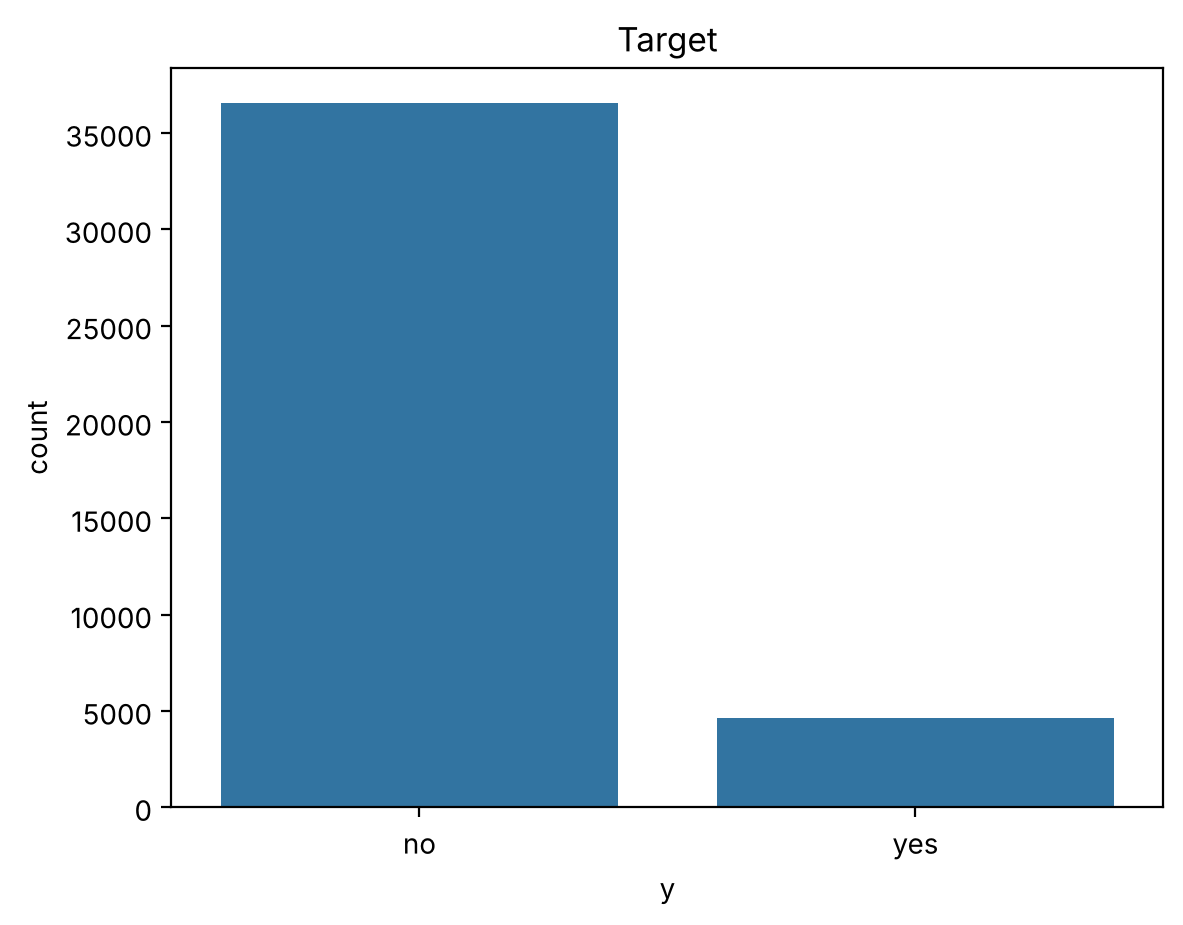

In [ ]:
sns.countplot(x=df["y"])
plt.title("Target")
plt.show()

# Task 2 — Missing values, duplicates, outliers

### Missing values

In [ ]:
print("NaN cells:", df.isna().sum().sum())

NaN cells: 0


In [ ]:
# hidden missing values
hidden = (df == "unknown").sum()
hidden["pdays = 999"] = (df["pdays"] == 999).sum()
hidden[hidden > 0].sort_values(ascending=True).to_frame("count")

,count
marital,80
job,330
loan,990
housing,990
education,1731
default,8597
pdays = 999,39673


### Duplicates

In [ ]:
print("Before:", len(df))
df = df.drop_duplicates().reset_index(drop=True) 
print("After :", len(df))

Before: 41188
After : 41176


### Clean (fixed rules, before split)

In [ ]:
df["y"] = (df["y"] == "yes").astype(int)

# pdays = 999 means "never contacted" -> flag, then drop pdays (96% is 999)
df["prev_contacted"] = (df["pdays"] != 999).astype(int)
df = df.drop(columns="pdays")

# education has a real order -> ordinal, "unknown" -> NaN
education_order = {
    "illiterate": 0, "basic.4y": 1, "basic.6y": 2, "basic.9y": 3,
    "high.school": 4, "professional.course": 5, "university.degree": 6
}
df["education"] = df["education"].map(education_order)
print("education NaN:", df["education"].isna().sum())

education NaN: 1730


- other `"unknown"` values (job, marital, default, housing, loan) stay as a category
- `month`, `day_of_week` have no year → not a real date → categories
- `duration`: UCI note — *"the duration is not known before a call is performed … should be discarded if the intention is to have a realistic predictive model."* → not used in the model (only one benchmark test in 6.6)

### Outliers

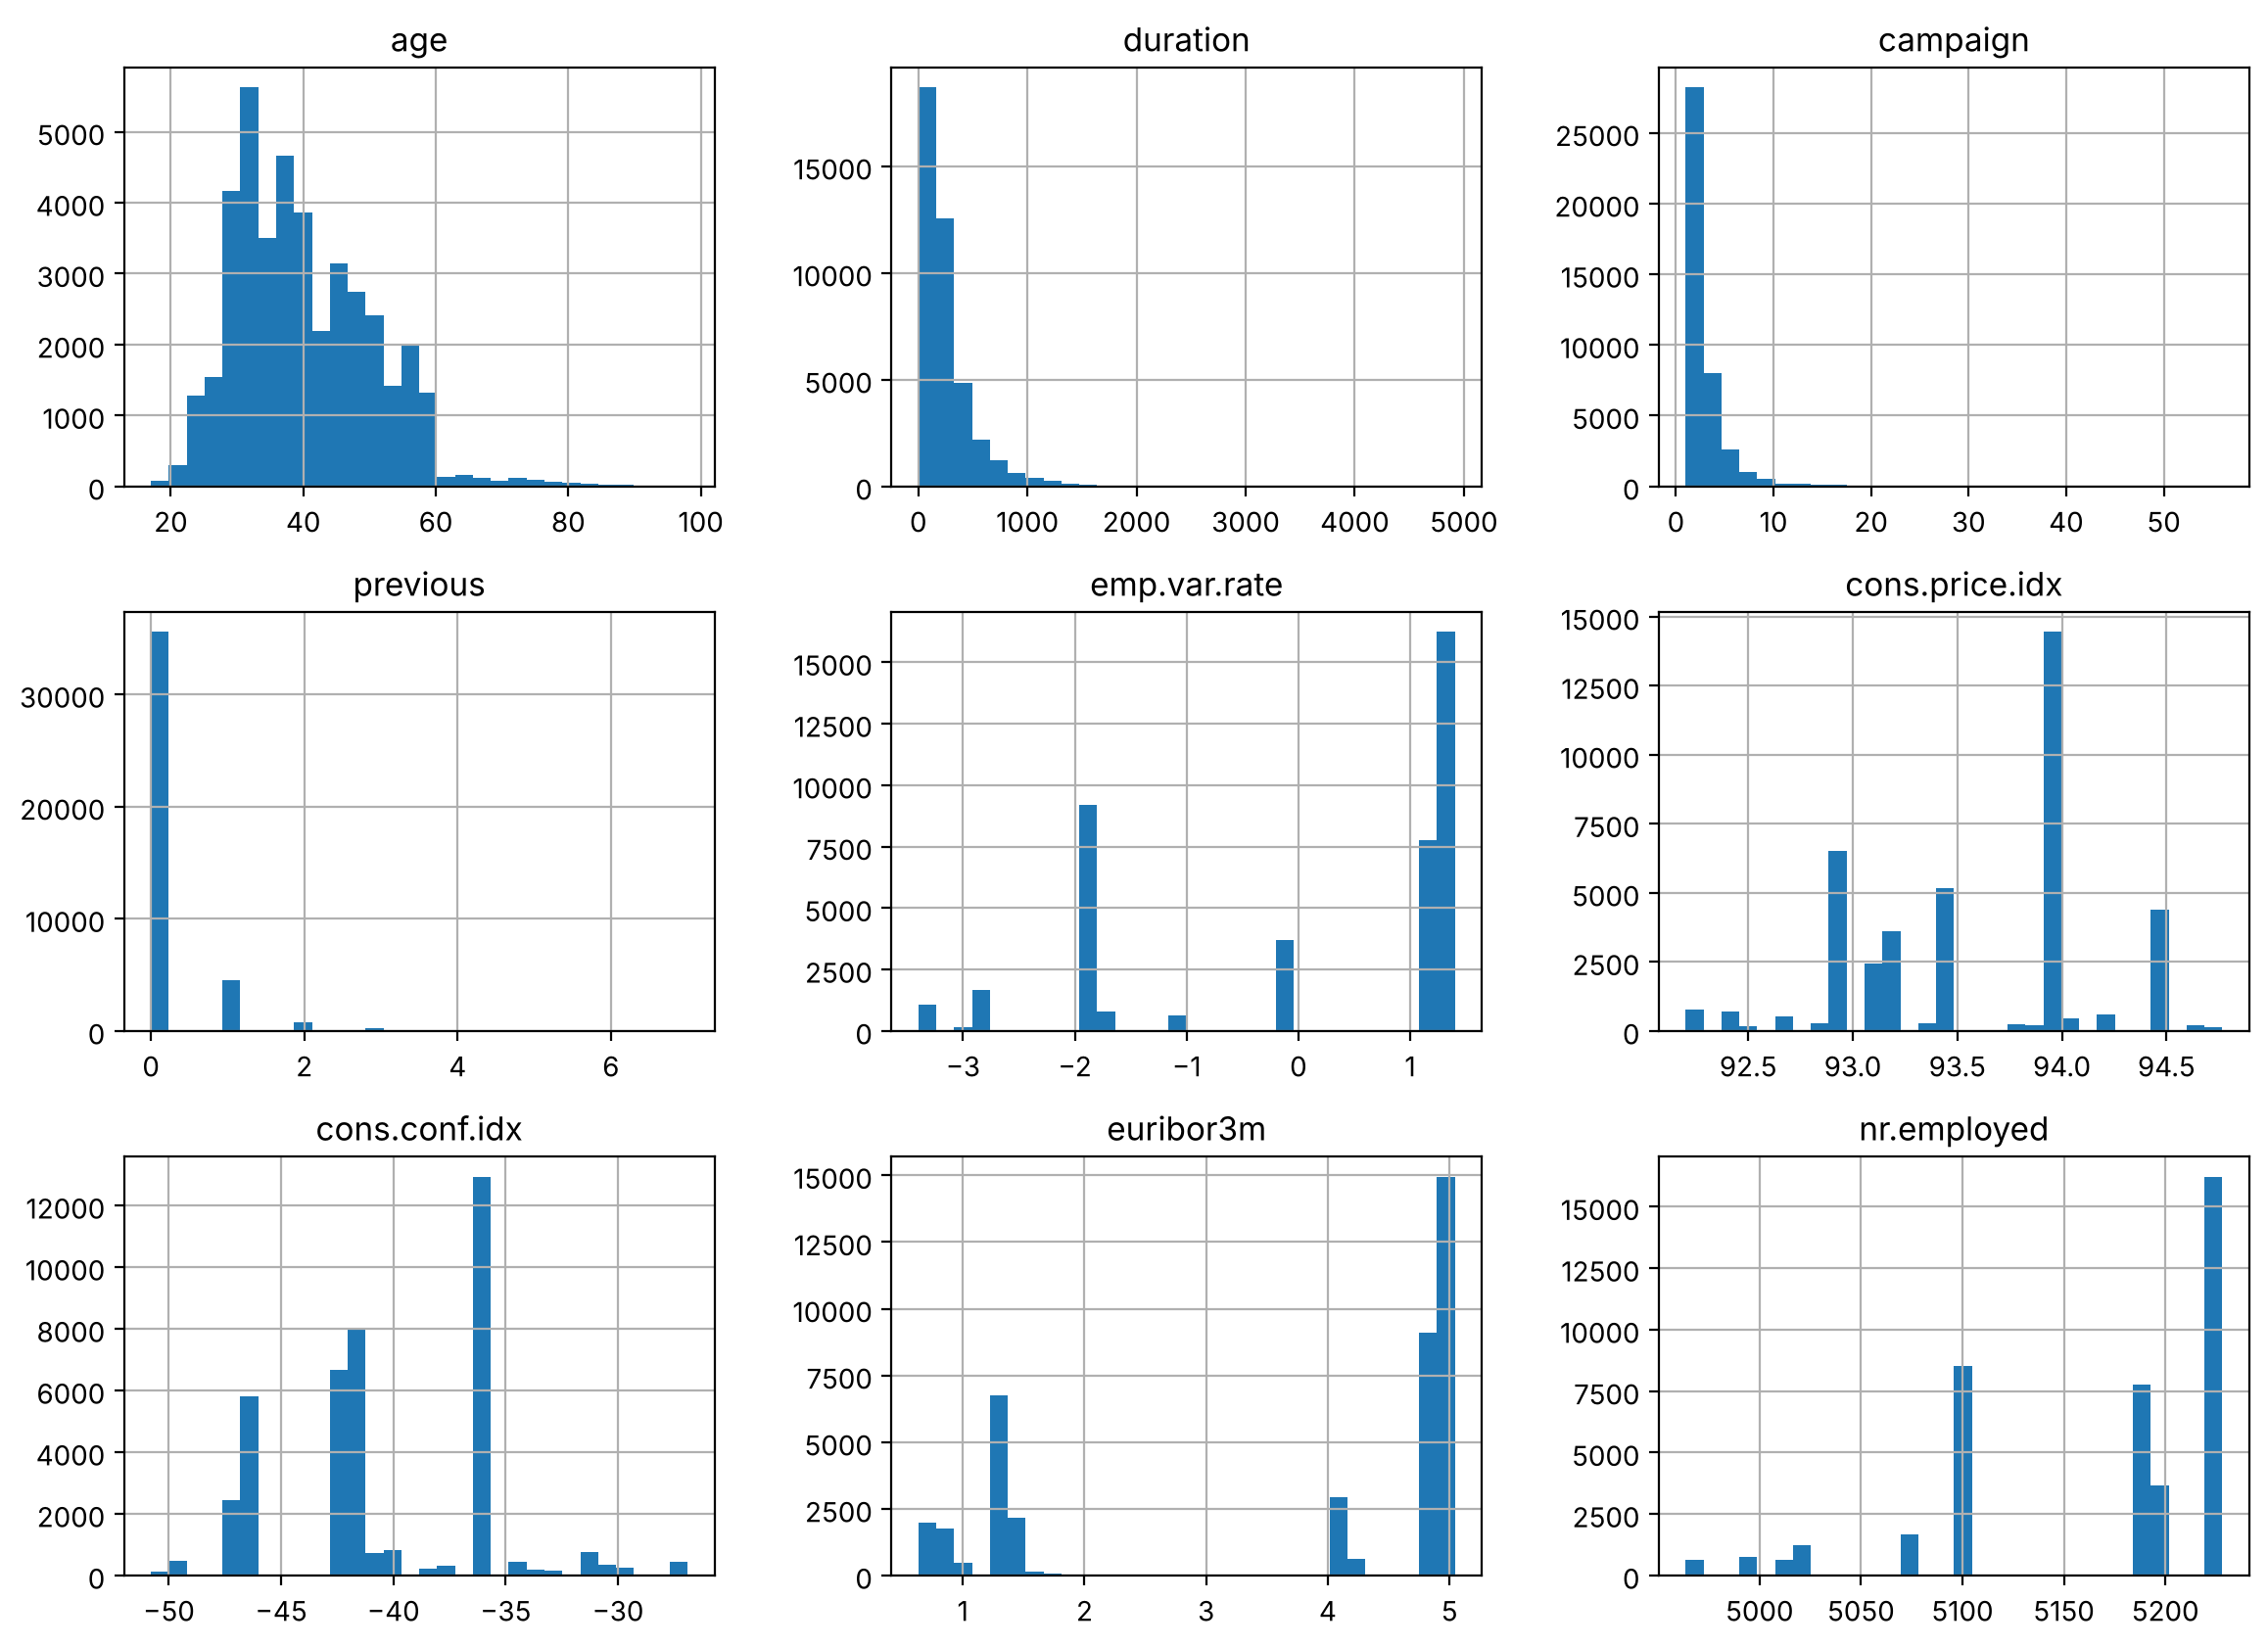

In [ ]:
numeric_cols = ["age", "duration", "campaign", "previous", "emp.var.rate",
                "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]

df[numeric_cols].hist(figsize=(14, 10), bins=30)
plt.show()

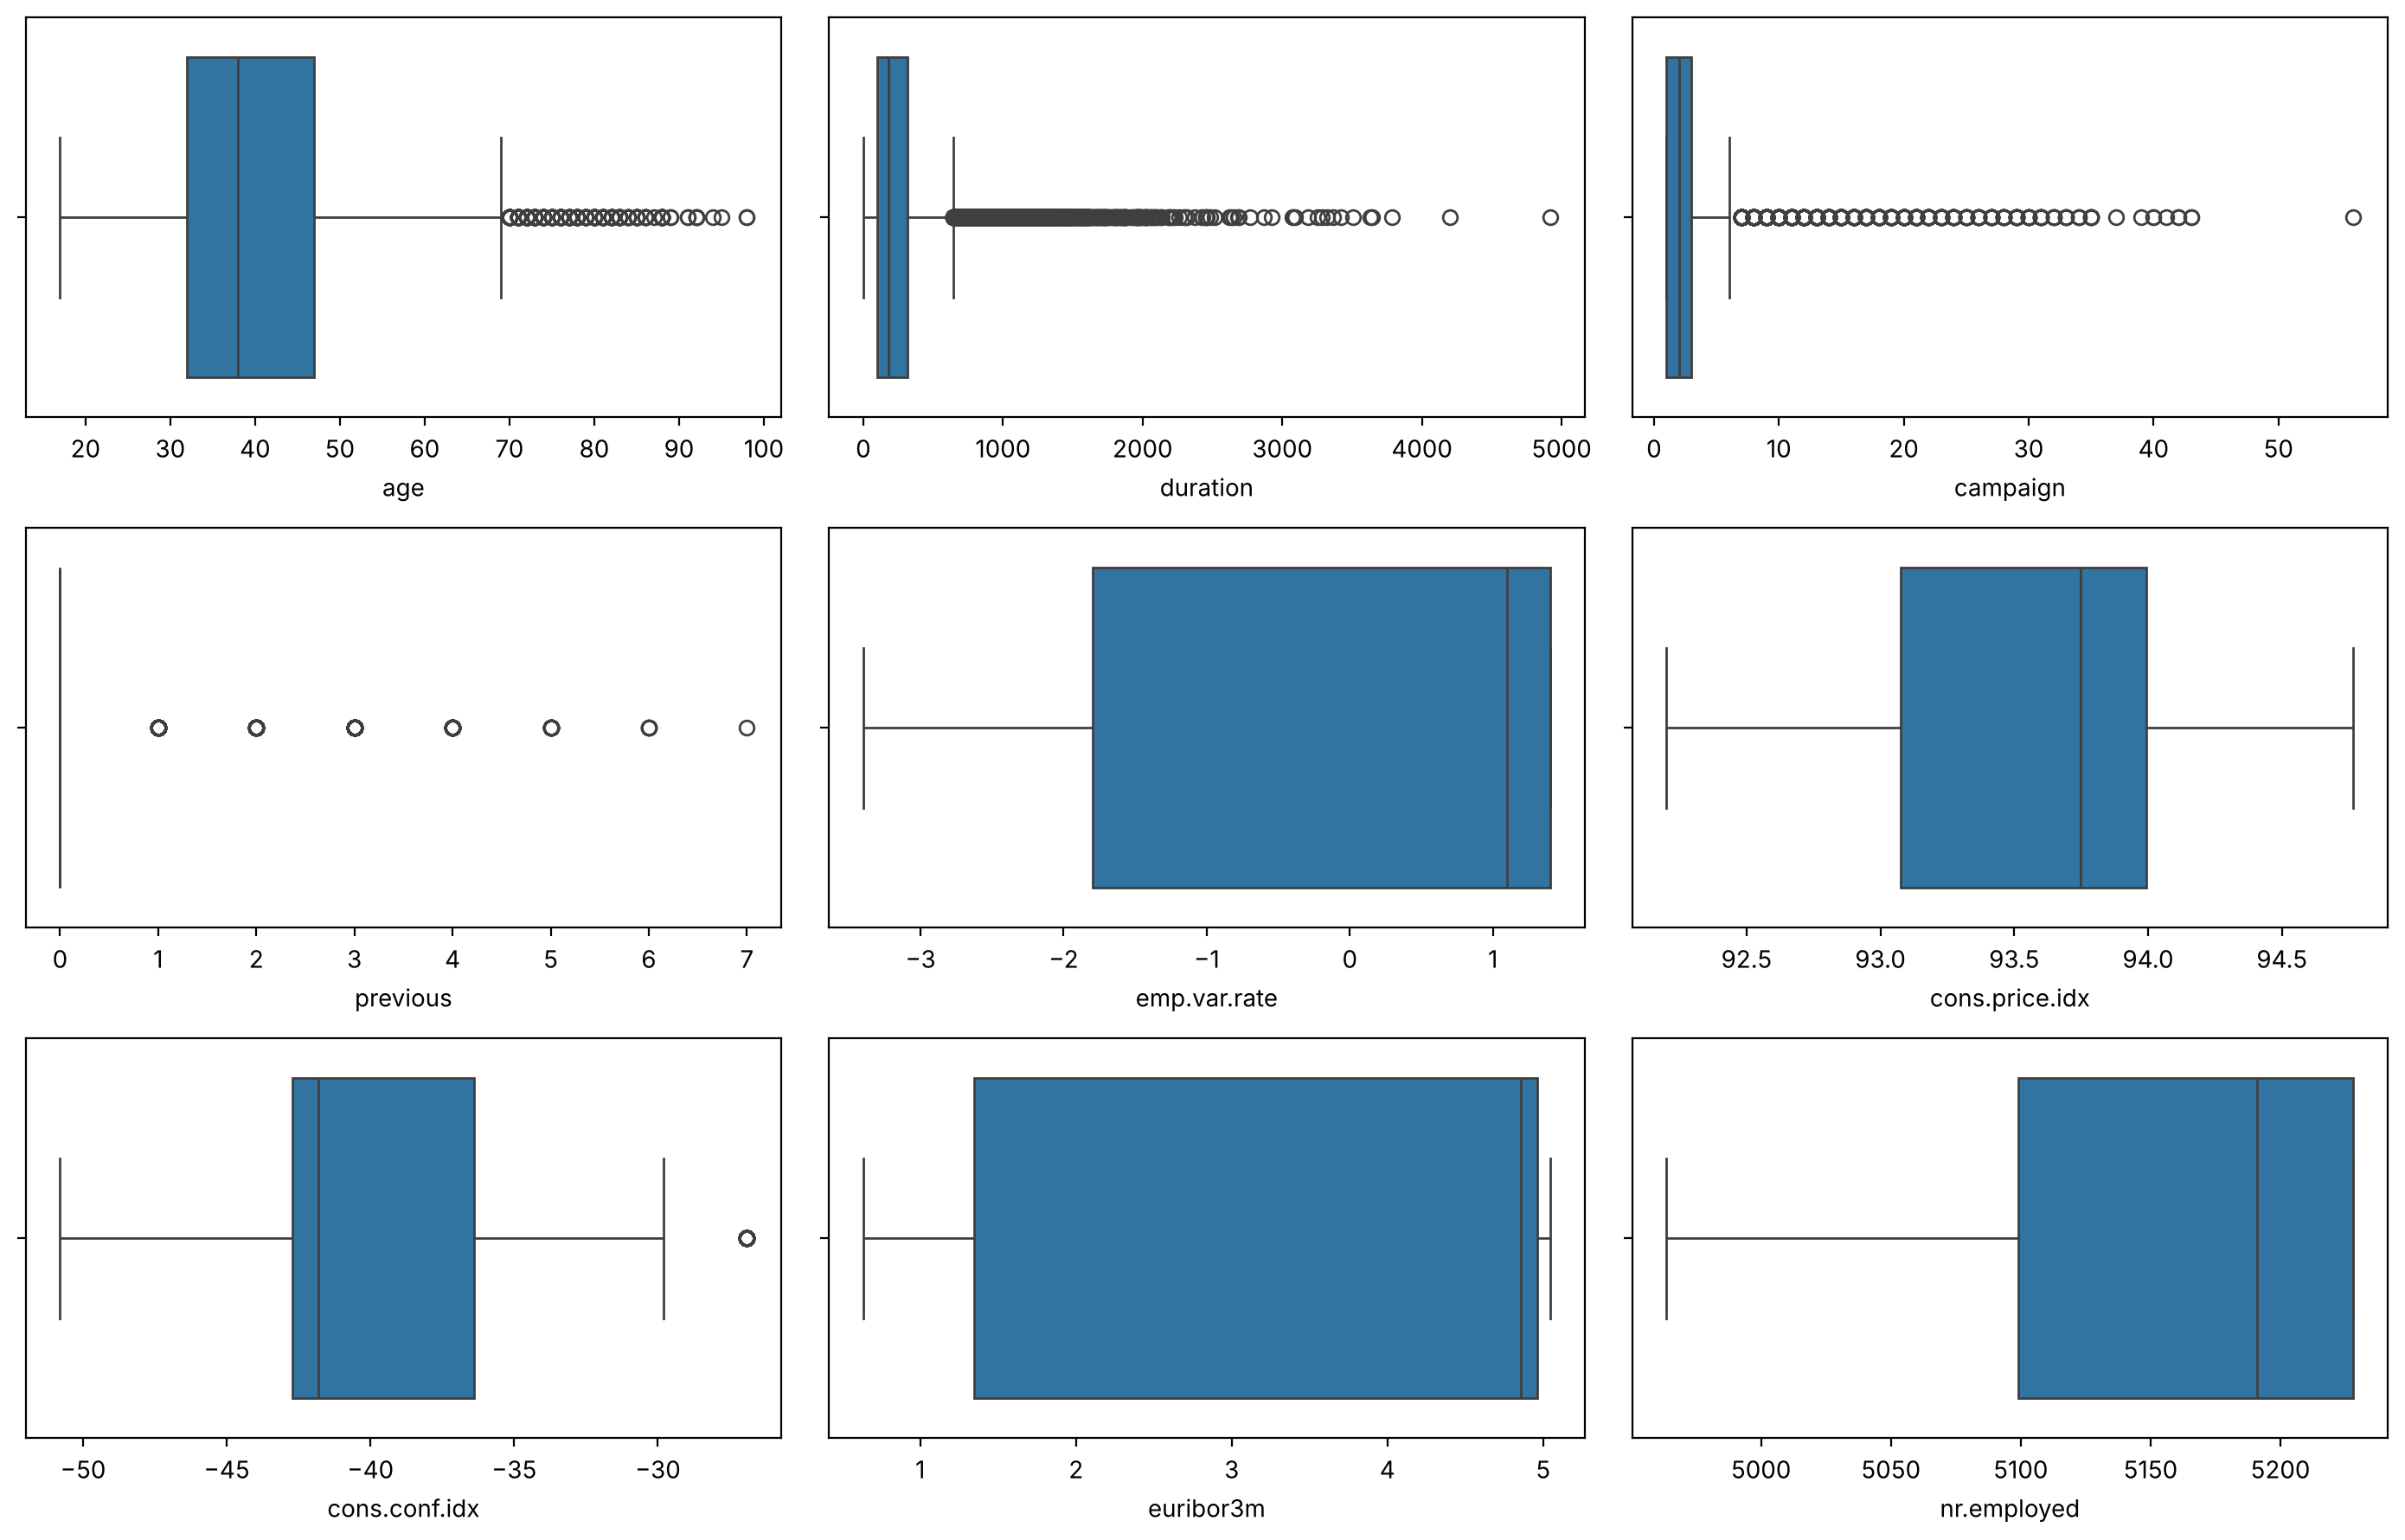

In [ ]:
fig, axes = plt.subplots(3, 3, figsize=(14, 9))
for ax, col in zip(axes.ravel(), numeric_cols):
    sns.boxplot(x=df[col], ax=ax)
plt.tight_layout()
plt.show()

In [ ]:
rows = []
for col in numeric_cols:
    skew = df[col].skew()
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    iqr_out = ((df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)).sum()
    z_out = (((df[col] - df[col].mean()) / df[col].std()).abs() > 3).sum()
    shape = "symmetric" if abs(skew) < 0.5 else ("moderate" if abs(skew) <= 1 else "strong")
    rows.append([col, round(skew, 3), shape, df[col].min(), df[col].max(), q1, q3, iqr, iqr_out, z_out])

outliers = pd.DataFrame(rows, columns=["column", "skew", "shape", "min", "max", "Q1", "Q3", "IQR", "IQR outliers", "|Z|>3"])
outliers = outliers.set_index("column")
outliers

,skew,shape,min,max,Q1,Q3,IQR,IQR outliers,|Z|>3
column,,,,,,,,,
age,0.785,moderate,17.000,98.000,32.000,47.000,15.000,468,369
duration,3.263,strong,0.000,4918.000,102.000,319.000,217.000,2963,861
campaign,4.762,strong,1.000,56.000,1.000,3.000,2.000,2406,869
previous,3.831,strong,0.000,7.000,0.000,0.000,0.000,5625,1064
emp.var.rate,-0.724,moderate,-3.400,1.400,-1.800,1.400,3.200,0,0
cons.price.idx,-0.231,symmetric,92.201,94.767,93.075,93.994,0.919,0,0
cons.conf.idx,0.303,symmetric,-50.800,-26.900,-42.700,-36.400,6.300,446,0
euribor3m,-0.709,moderate,0.634,5.045,1.344,4.961,3.617,0,0
nr.employed,-1.044,strong,4963.600,5228.100,5099.100,5228.100,129.000,0,0


Skewness: |skew| < 0.5 symmetric · 0.5 – 1 moderate · > 1 strong

In [ ]:
outliers["decision"] = ["keep", "IQR clip", "IQR clip", "keep", "keep",
                        "Z-score check", "Z-score check", "keep", "keep"]
outliers["why"] = [
    "valid ages (17-98)",
    "strong skew (benchmark only)",
    "strong skew",
    "count, IQR = 0 would remove all non-zero values",
    "few fixed economic levels",
    "symmetric, |Z|>3 = 0 -> nothing to clip",
    "symmetric, |Z|>3 = 0 -> nothing to clip",
    "few fixed economic levels",
    "few fixed economic levels",
]
outliers[["skew", "shape", "IQR", "IQR outliers", "|Z|>3", "decision", "why"]]

,skew,shape,IQR,IQR outliers,|Z|>3,decision,why
column,,,,,,,
age,0.785,moderate,15.000,468,369,keep,valid ages (17-98)
duration,3.263,strong,217.000,2963,861,IQR clip,strong skew (benchmark only)
campaign,4.762,strong,2.000,2406,869,IQR clip,strong skew
previous,3.831,strong,0.000,5625,1064,keep,"count, IQR = 0 would remove all non-zero values"
emp.var.rate,-0.724,moderate,3.200,0,0,keep,few fixed economic levels
cons.price.idx,-0.231,symmetric,0.919,0,0,Z-score check,"symmetric, |Z|>3 = 0 -> nothing to clip"
cons.conf.idx,0.303,symmetric,6.300,446,0,Z-score check,"symmetric, |Z|>3 = 0 -> nothing to clip"
euribor3m,-0.709,moderate,3.617,0,0,keep,few fixed economic levels
nr.employed,-1.044,strong,129.000,0,0,keep,few fixed economic levels


Outliers are capped, not removed (no rows deleted). Only `duration` and `campaign` are clipped.

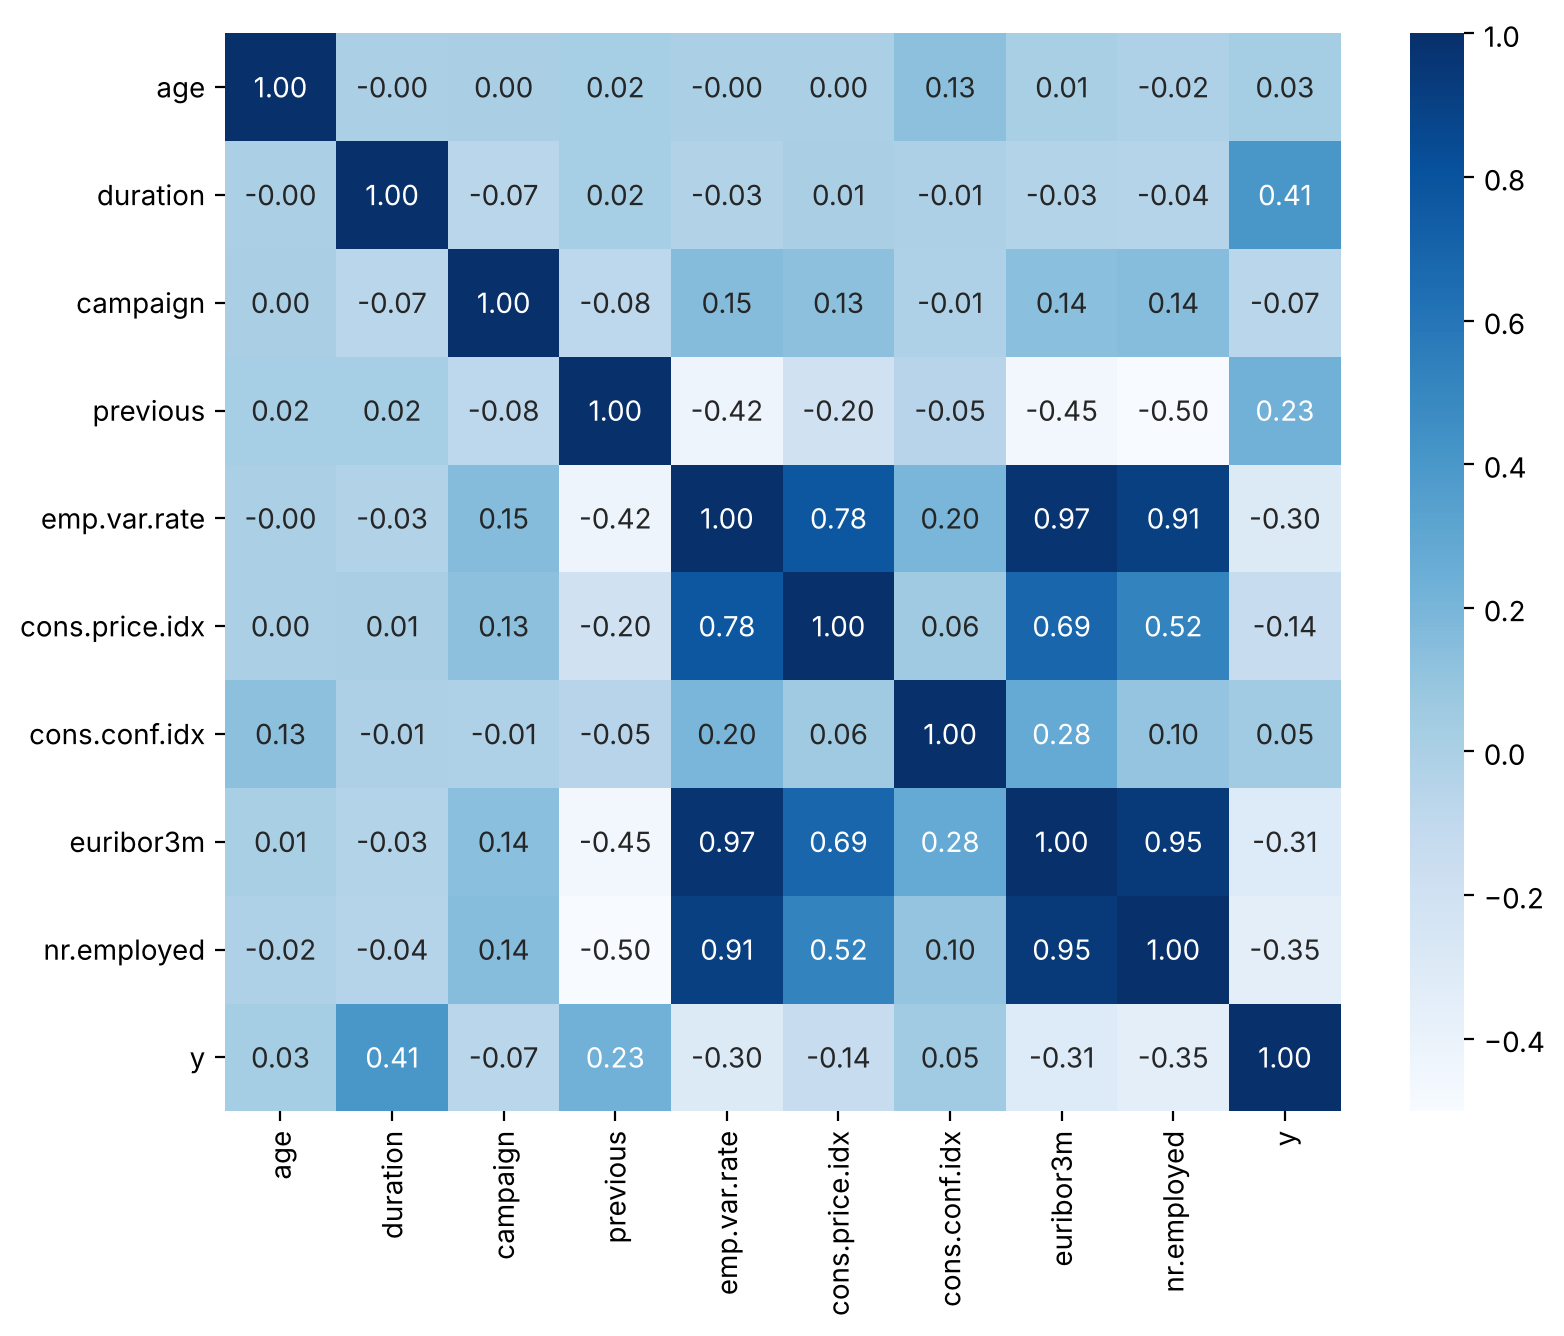

In [ ]:
plt.figure(figsize=(9, 7))
sns.heatmap(df[numeric_cols + ["y"]].corr(), annot=True, fmt=".2f", cmap="Blues")
plt.show()

# Split

In [ ]:
X = df.drop(columns="y")
y = df["y"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=SEED,
    stratify=y          # keep the same class % in Train and Test
)

pd.DataFrame({"rows": [len(y_train), len(y_test)],
              "yes %": [round(y_train.mean() * 100, 2), round(y_test.mean() * 100, 2)]},
             index=["Train", "Test"])

,rows,yes %
Train,32940,11.27
Test,8236,11.27


### Impute (learn from Train)

In [ ]:
value = X_train["education"].median()               # learned on Train
X_train["education"] = X_train["education"].fillna(value)
X_test["education"] = X_test["education"].fillna(value)
print("education -> median =", value)

education -> median = 4.0


### Outliers (learn from Train)

In [ ]:
iqr_cols = ["duration", "campaign"]
for col in iqr_cols:
    q1 = X_train[col].quantile(0.25)                # learned on Train
    q3 = X_train[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    print(col, "limits:", round(lower, 2), "to", round(upper, 2))
    X_train[col] = X_train[col].clip(lower, upper)
    X_test[col] = X_test[col].clip(lower, upper)    # same bounds on Test

duration limits: -223.5 to 644.5
campaign limits: -2.0 to 6.0


In [ ]:
# symmetric columns -> Z-score check (learned on Train)
for col in ["cons.price.idx", "cons.conf.idx"]:
    mean = X_train[col].mean()
    std = X_train[col].std()
    print(col, "-> |Z| > 3 in Train:", (((X_train[col] - mean) / std).abs() > 3).sum())

cons.price.idx -> |Z| > 3 in Train: 0
cons.conf.idx -> |Z| > 3 in Train: 0


# Task 3 — Encoding and scaling

### One-Hot Encoding (no real order)

In [ ]:
nominal_cols = ["job", "marital", "default", "housing", "loan",
                "contact", "month", "day_of_week", "poutcome"]

onehot_table = pd.DataFrame({
    "categories": [", ".join(sorted(X_train[c].unique())) for c in nominal_cols],
    "new columns": [X_train[c].nunique() for c in nominal_cols]
}, index=nominal_cols)
onehot_table

,categories,new columns
job,"admin., blue-collar, entrepreneur, housemaid, ...",12
marital,"divorced, married, single, unknown",4
default,"no, unknown, yes",3
housing,"no, unknown, yes",3
loan,"no, unknown, yes",3
contact,"cellular, telephone",2
month,"apr, aug, dec, jul, jun, mar, may, nov, oct, sep",10
day_of_week,"fri, mon, thu, tue, wed",5
poutcome,"failure, nonexistent, success",3


In [ ]:
columns_before = X_train.shape[1]

encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False).set_output(transform="pandas")

train_encoded = encoder.fit_transform(X_train[nominal_cols])   # LEARN + transform
test_encoded = encoder.transform(X_test[nominal_cols])         # apply same categories

X_train = pd.concat([X_train.drop(columns=nominal_cols), train_encoded], axis=1)
X_test = pd.concat([X_test.drop(columns=nominal_cols), test_encoded], axis=1)

pd.DataFrame({"before": [columns_before - len(nominal_cols), len(nominal_cols), columns_before],
              "after": [columns_before - len(nominal_cols), train_encoded.shape[1], X_train.shape[1]]},
             index=["numerical", "categorical", "total"])

,before,after
numerical,11,11
categorical,9,45
total,20,56


In [ ]:
# example: one column -> 0/1 columns
train_encoded.filter(like="contact").head()

,contact_cellular,contact_telephone
36444,1.0,0.0
1233,0.0,1.0
24104,0.0,1.0
15513,0.0,1.0
17912,1.0,0.0


### Scaling

In [ ]:
standard_cols = ["age", "education", "emp.var.rate", "euribor3m", "cons.price.idx", "cons.conf.idx"]
robust_cols = ["duration", "campaign", "previous", "nr.employed"]

standard_scaler = StandardScaler()
X_train[standard_cols] = standard_scaler.fit_transform(X_train[standard_cols])
X_test[standard_cols] = standard_scaler.transform(X_test[standard_cols])

robust_scaler = RobustScaler()
X_train[robust_cols] = robust_scaler.fit_transform(X_train[robust_cols])
X_test[robust_cols] = robust_scaler.transform(X_test[robust_cols])

pd.DataFrame({"scaler": ["StandardScaler"] * len(standard_cols) + ["RobustScaler"] * len(robust_cols),
              "why": ["symmetric / moderate"] * len(standard_cols) + ["strong skew"] * len(robust_cols)},
             index=standard_cols + robust_cols)

,scaler,why
age,StandardScaler,symmetric / moderate
education,StandardScaler,symmetric / moderate
emp.var.rate,StandardScaler,symmetric / moderate
euribor3m,StandardScaler,symmetric / moderate
cons.price.idx,StandardScaler,symmetric / moderate
cons.conf.idx,StandardScaler,symmetric / moderate
duration,RobustScaler,strong skew
campaign,RobustScaler,strong skew
previous,RobustScaler,strong skew
nr.employed,RobustScaler,strong skew


In [ ]:
print("Train NaN:", X_train.isna().sum().sum(), "| Test NaN:", X_test.isna().sum().sum())
print("Non-numeric columns:", X_train.select_dtypes(exclude="number").columns.tolist())
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train NaN: 0 | Test NaN: 0
Non-numeric columns: []
Train: (32940, 56) | Test: (8236, 56)


### Validation set
All comparisons use a validation set taken from Train. The Test set is used **once**, at the end.

In [ ]:
tr_idx, val_idx = train_test_split(X_train.index, train_size=12000, test_size=5000,
                                   stratify=y_train, random_state=SEED)

def evaluate(model, cols, data=X_train):
    model.fit(data.loc[tr_idx, cols], y_train.loc[tr_idx])
    pred = model.predict(data.loc[val_idx, cols])
    y_val = y_train.loc[val_idx]
    return [round(accuracy_score(y_val, pred), 4), round(precision_score(y_val, pred), 4),
            round(recall_score(y_val, pred), 4), round(f1_score(y_val, pred), 4)]

metrics = ["accuracy", "precision", "recall", "f1"]

# Task 4 — Feature selection (on Train only)

### 4.1 Variance Threshold

In [ ]:
vt = VarianceThreshold(threshold=0.001)
vt.fit(X_train)

variance = pd.DataFrame({"variance": vt.variances_,
                         "keep": vt.get_support()},      # False = variance < 0.001
                        index=X_train.columns)
variance.sort_values("variance").round(4)

,variance,keep
default_yes,0.0001,False
marital_unknown,0.0021,True
month_dec,0.0044,True
job_unknown,0.0080,True
month_mar,0.0129,True
month_sep,0.0138,True
month_oct,0.0173,True
job_student,0.0205,True
housing_unknown,0.0231,True
loan_unknown,0.0231,True


### 4.2 Correlation

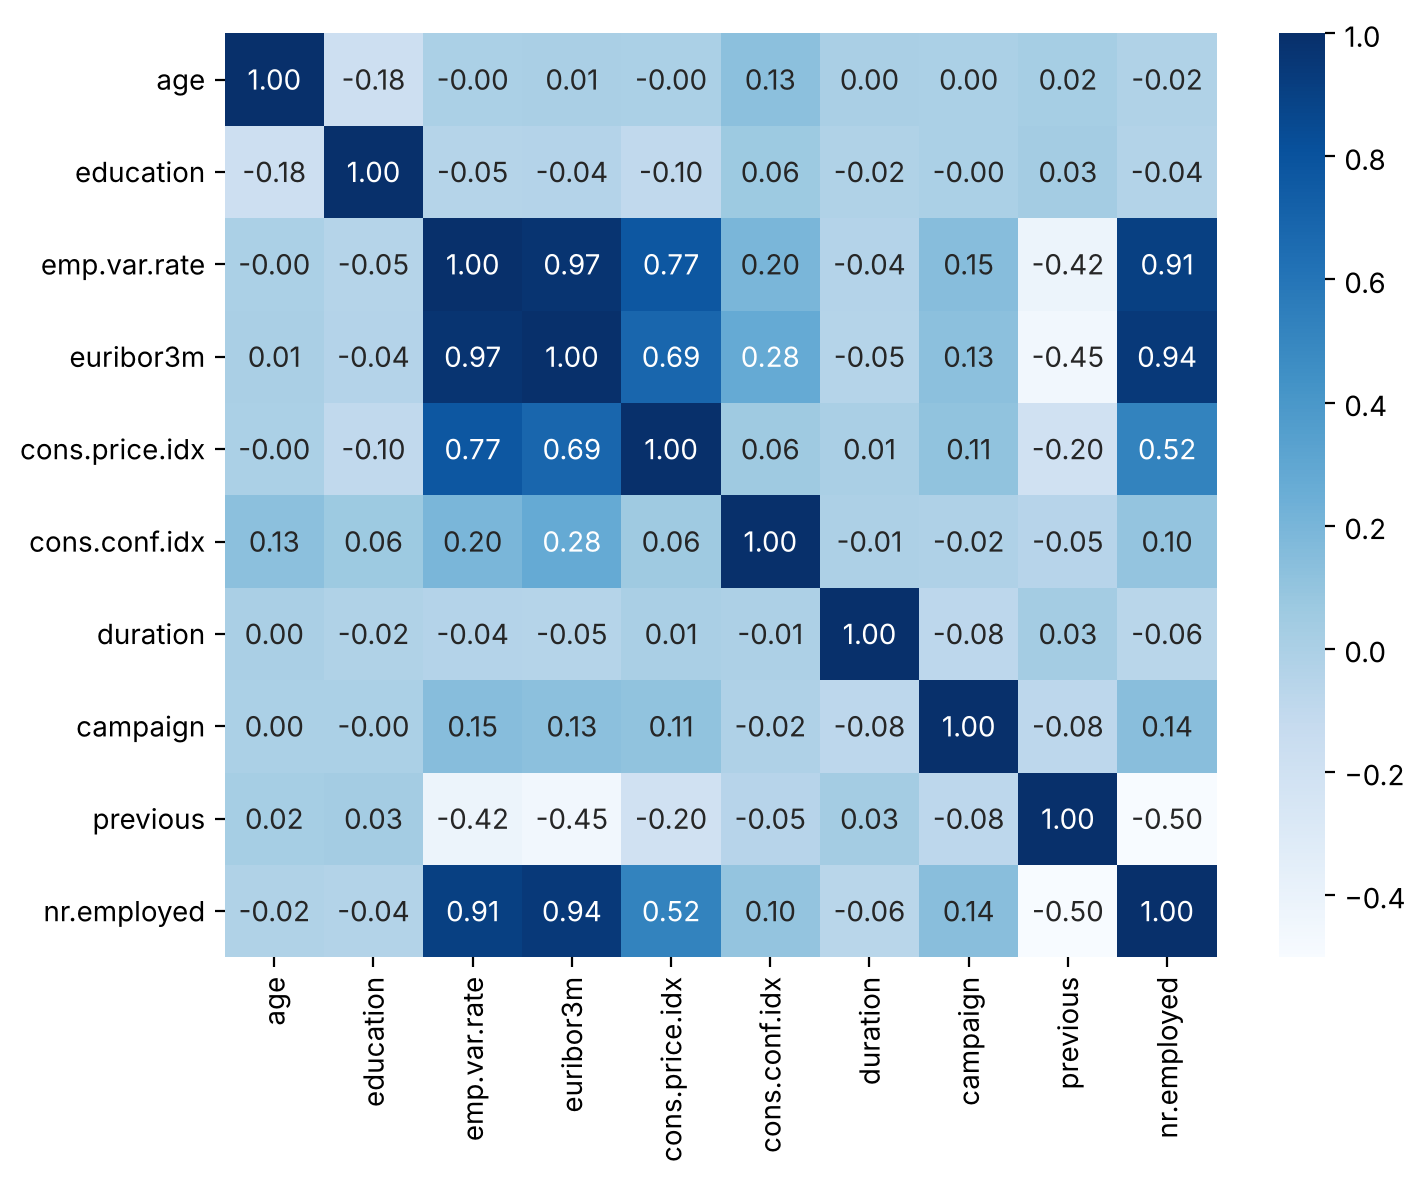

In [ ]:
num = standard_cols + robust_cols
plt.figure(figsize=(8, 6))
sns.heatmap(X_train[num].corr(), annot=True, fmt=".2f", cmap="Blues")
plt.show()

In [ ]:
corr = X_train[num].corr().abs()
pairs = [(a, b, round(corr.loc[a, b], 3)) for i, a in enumerate(num) for b in num[i + 1:] if corr.loc[a, b] > 0.9]
pd.DataFrame(pairs, columns=["feature 1", "feature 2", "|corr|"])

,feature 1,feature 2,|corr|
0,emp.var.rate,euribor3m,0.972
1,emp.var.rate,nr.employed,0.906
2,euribor3m,nr.employed,0.945


### 4.3 Chi² · ANOVA F-test · Mutual Information

#### Chi-square

In [ ]:
# Chi2 needs values >= 0, so we make a MinMax copy of X_train (used only for this test)
X_mm = MinMaxScaler().fit_transform(X_train)

chi_scores, chi_p = chi2(X_mm, y_train)

chi_table = pd.DataFrame({"Chi2": chi_scores}, index=X_train.columns)

print("Chi-square - top 10 features:")
print(chi_table.sort_values("Chi2", ascending=False).head(10).round(4))
#<0.05 -> true valuee

Chi-square - top 10 features:
                        Chi2  Chi2_p
prev_contacted     3437.4302     0.0
poutcome_success   3278.0603     0.0
duration           1101.6369     0.0
euribor3m           693.9155     0.0
month_mar           640.6277     0.0
month_oct           605.5872     0.0
month_sep           495.1804     0.0
contact_telephone   443.0064     0.0
emp.var.rate        419.8639     0.0
nr.employed         393.7132     0.0


#### ANOVA F-test

In [ ]:
f_scores, f_p = f_classif(X_train, y_train)

anova_table = pd.DataFrame({"ANOVA_F": f_scores}, index=X_train.columns)

print("ANOVA F-test - top 10 features:")
print(anova_table.sort_values("ANOVA_F", ascending=False).head(10).round(4))

ANOVA F-test - top 10 features:
                        ANOVA_F  ANOVA_p
duration              6325.8076      0.0
nr.employed           4603.7052      0.0
prev_contacted        4001.4065      0.0
poutcome_success      3779.5077      0.0
euribor3m             3338.0686      0.0
emp.var.rate          3107.8500      0.0
previous              1822.6854      0.0
poutcome_nonexistent  1278.6242      0.0
contact_cellular       711.9315      0.0
contact_telephone      711.9315      0.0


#### Mutual Information

In [ ]:
mi_scores = mutual_info_classif(X_train, y_train, random_state=SEED)

mi_table = pd.DataFrame({"MI": mi_scores}, index=X_train.columns)

print("Mutual Information - top 10 features:")
print(mi_table.sort_values("MI", ascending=False).head(10).round(4))

Mutual Information - top 10 features:
                          MI
duration              0.0734
euribor3m             0.0723
cons.price.idx        0.0676
cons.conf.idx         0.0664
nr.employed           0.0604
emp.var.rate          0.0549
prev_contacted        0.0337
poutcome_success      0.0289
poutcome_nonexistent  0.0198
previous              0.0177


In [ ]:
# put the 3 methods in one table (used in 4.4)
scores = pd.concat([chi_table, anova_table, mi_table], axis=1).round(4)
print("Number of features:", len(scores))

Number of features: 56


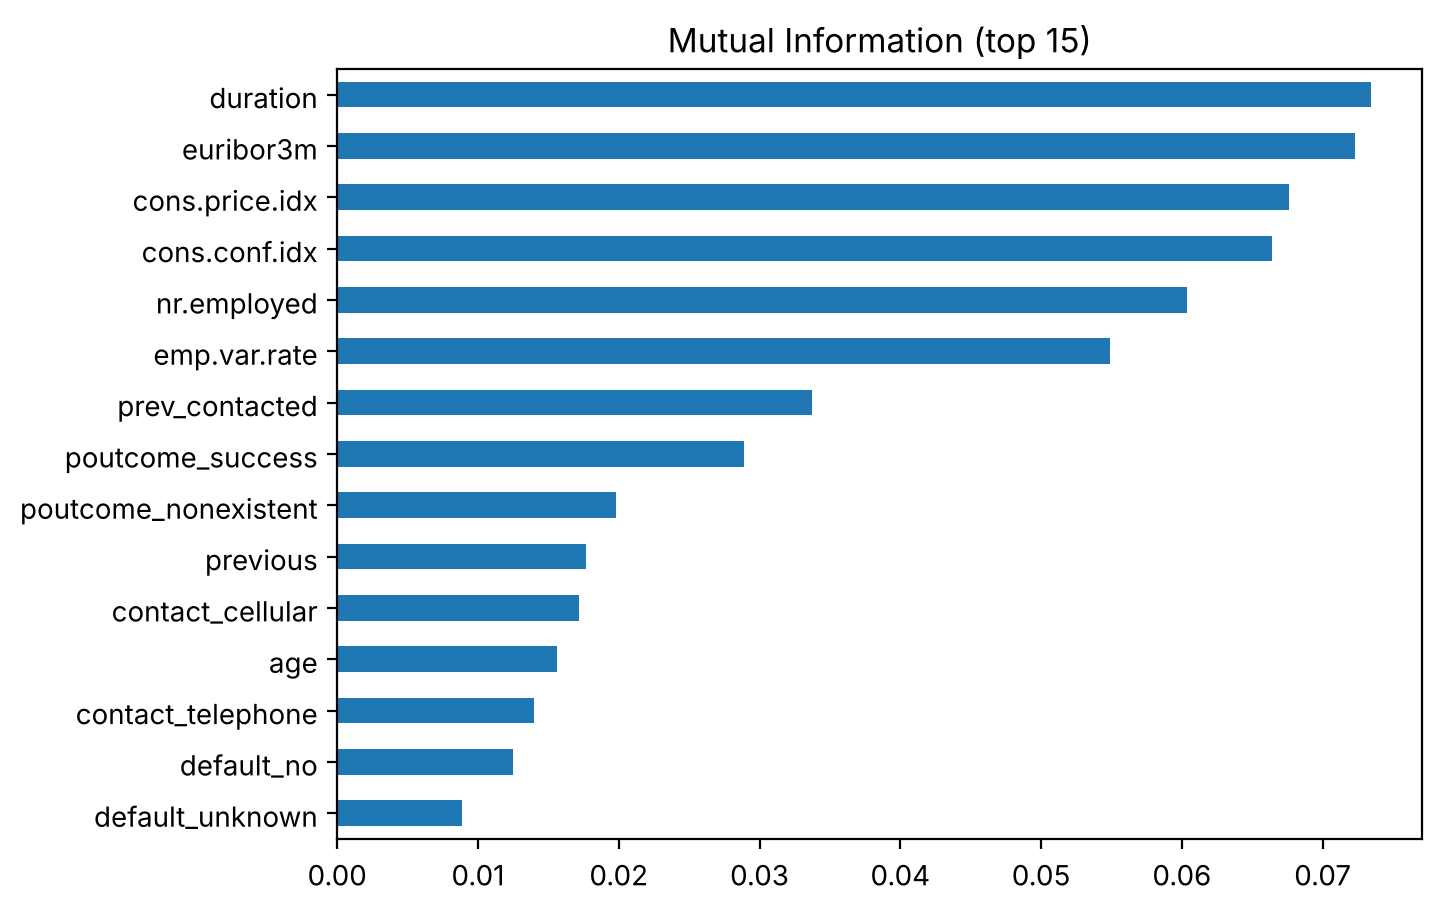

In [ ]:
scores["MI"].sort_values().tail(15).plot(kind="barh", figsize=(7, 5))
plt.title("Mutual Information (top 15)")
plt.show()

### 4.4 Features to drop

In [ ]:
drop_cols = ["emp.var.rate", "nr.employed", "default_yes",
             "job_technician", "job_self-employed", "job_unknown", "job_management",
             "day_of_week_tue", "day_of_week_wed", "day_of_week_fri"]

reason = (["correlated > 0.9 with euribor3m"] * 2 + ["low variance"] +
          ["p > 0.05 in Chi2 and ANOVA, MI ≈ 0"] * 7)
scores.loc[drop_cols].assign(reason=reason)

,Chi2,Chi2_p,ANOVA_F,ANOVA_p,MI,reason
emp.var.rate,419.8639,0.0000,3107.8500,0.0000,0.0549,correlated > 0.9 with euribor3m
nr.employed,393.7132,0.0000,4603.7052,0.0000,0.0604,correlated > 0.9 with euribor3m
default_yes,0.2539,0.6143,0.2539,0.6143,0.0009,low variance
job_technician,1.5111,0.2190,1.8087,0.1787,0.0000,"p > 0.05 in Chi2 and ANOVA, MI ≈ 0"
job_self-employed,0.9905,0.3196,1.0251,0.3113,0.0000,"p > 0.05 in Chi2 and ANOVA, MI ≈ 0"
job_unknown,0.3194,0.5719,0.3220,0.5704,0.0000,"p > 0.05 in Chi2 and ANOVA, MI ≈ 0"
job_management,0.0006,0.9803,0.0007,0.9796,0.0000,"p > 0.05 in Chi2 and ANOVA, MI ≈ 0"
day_of_week_tue,0.0203,0.8866,0.0253,0.8737,0.0000,"p > 0.05 in Chi2 and ANOVA, MI ≈ 0"
day_of_week_wed,1.3151,0.2515,1.6408,0.2002,0.0000,"p > 0.05 in Chi2 and ANOVA, MI ≈ 0"
day_of_week_fri,0.6196,0.4312,0.7668,0.3812,0.0002,"p > 0.05 in Chi2 and ANOVA, MI ≈ 0"


### 4.5 Check: all features vs selected features (validation)

In [ ]:
all_cols = [c for c in X_train.columns if c != "duration"]
selected_cols = [c for c in all_cols if c not in drop_cols]

pd.DataFrame([evaluate(SVC(), all_cols), evaluate(SVC(), selected_cols)],
             index=[f"all ({len(all_cols)})", f"selected ({len(selected_cols)})"], columns=metrics)

,accuracy,precision,recall,f1
all (55),0.8988,0.6966,0.1794,0.2853
selected (45),0.8986,0.6944,0.1776,0.2829


In [ ]:
cols = selected_cols                 # features used by the model (no duration)
print(len(cols), "features used in the model")

45 features used in the model


# Task 5 — Distances


In [ ]:
# select 2 clients from each class (randomly)
selected_indices = []
for c in sorted(y_train.unique()):
    indices = y_train[y_train == c].sample(n=2, random_state=SEED).index.tolist()
    selected_indices.extend(indices)

sample = X_train.loc[selected_indices, cols]      # scaled, 45 features
print(y_train.loc[selected_indices])

3671     0
26048    0
27096    1
31866    1
Name: y, dtype: int64


In [ ]:
for metric in ["euclidean", "manhattan"]:
    d = pairwise_distances(sample, metric=metric)
    print(metric)
    print(pd.DataFrame(d, index=sample.index, columns=sample.index).round(2))
    print()

euclidean
       3671   26048  27096  31866
3671    0.00   3.49   4.27   5.64
26048   3.49   0.00   2.93   4.64
27096   4.27   2.93   0.00   4.16
31866   5.64   4.64   4.16   0.00

manhattan
       3671   26048  27096  31866
3671    0.00  12.22  18.16  21.62
26048  12.22   0.00   9.13  17.59
27096  18.16   9.13   0.00  15.46
31866  21.62  17.59  15.46   0.00



In [ ]:
from itertools import combinations     # every pair once, without a client with itself

results = []
for i, j in combinations(selected_indices, 2):
    A = sample.loc[i]
    B = sample.loc[j]

    if y_train.loc[i] == y_train.loc[j]:
        pair_type = "Same Class"
    else:
        pair_type = "Different Classes"

    euclidean = np.sqrt(((A - B) ** 2).sum())     # straight line
    manhattan = np.abs(A - B).sum()               # sum of differences
    results.append([i, j, pair_type, euclidean, manhattan])

results_df = pd.DataFrame(results, columns=["Client 1", "Client 2", "Pair Type", "Euclidean", "Manhattan"])
results_df.round(2)

,Client 1,Client 2,Pair Type,Euclidean,Manhattan
0,3671,26048,Same Class,3.49,12.22
1,3671,27096,Different Classes,4.27,18.16
2,3671,31866,Different Classes,5.64,21.62
3,26048,27096,Different Classes,2.93,9.13
4,26048,31866,Different Classes,4.64,17.59
5,27096,31866,Same Class,4.16,15.46


In [ ]:
comparison = results_df.groupby("Pair Type")[["Euclidean", "Manhattan"]].mean()
comparison.round(2)

,Euclidean,Manhattan
Pair Type,,
Different Classes,4.37,16.63
Same Class,3.82,13.84


# Task 6 — SVM

No GridSearch: each parameter is changed manually and checked on the **validation** set.
Models are compared with **F1** (accuracy alone is misleading: always saying "no" gives 0.887).

### 6.1 Class weight (penalty)

In [ ]:
weights_res = pd.DataFrame([evaluate(SVC(), cols),
                            evaluate(SVC(class_weight="balanced"), cols)],
                           index=["no class_weight", "class_weight='balanced'"], columns=metrics)
weights_res

,accuracy,precision,recall,f1
no class_weight,0.8986,0.6944,0.1776,0.2829
class_weight='balanced',0.8496,0.3882,0.5826,0.4659


### 6.2 All features vs selected features (with class_weight)

In [ ]:
selection_res = pd.DataFrame([evaluate(SVC(class_weight="balanced"), all_cols),
                              evaluate(SVC(class_weight="balanced"), selected_cols)],
                             index=[f"all ({len(all_cols)})", f"selected ({len(selected_cols)})"], columns=metrics)
selection_res

,accuracy,precision,recall,f1
all (55),0.8488,0.3871,0.5879,0.4669
selected (45),0.8496,0.3882,0.5826,0.4659


### 6.3 Linear — try C

In [ ]:
results = []
for C in [0.01, 0.1, 1, 10]:
    model = SVC(kernel="linear", C=C, class_weight="balanced")
    results.append(["linear", f"C={C}"] + evaluate(model, cols))

linear_res = pd.DataFrame(results, columns=["kernel", "params"] + metrics)
linear_res

,kernel,params,accuracy,precision,recall,f1
0,linear,C=0.01,0.7248,0.2445,0.6909,0.3612
1,linear,C=0.1,0.8352,0.3583,0.5861,0.4447
2,linear,C=1,0.8368,0.3611,0.5844,0.4464
3,linear,C=10,0.8368,0.3611,0.5844,0.4464


### 6.4 RBF — try C and gamma

In [ ]:
results = []
for C in [0.1, 1, 10]:
    for gamma in [0.01, "scale", 0.1]:
        model = SVC(kernel="rbf", C=C, gamma=gamma, class_weight="balanced")
        results.append(["rbf", f"C={C}, gamma={gamma}"] + evaluate(model, cols))

rbf_res = pd.DataFrame(results, columns=["kernel", "params"] + metrics)
rbf_res

,kernel,params,accuracy,precision,recall,f1
0,rbf,"C=0.1, gamma=0.01",0.7248,0.2445,0.6909,0.3612
1,rbf,"C=0.1, gamma=scale",0.8428,0.3743,0.5897,0.4579
2,rbf,"C=0.1, gamma=0.1",0.8434,0.3750,0.5861,0.4574
3,rbf,"C=1, gamma=0.01",0.8360,0.3602,0.5879,0.4467
4,rbf,"C=1, gamma=scale",0.8496,0.3882,0.5826,0.4659
5,rbf,"C=1, gamma=0.1",0.8434,0.3733,0.5755,0.4528
6,rbf,"C=10, gamma=0.01",0.8476,0.3839,0.5844,0.4634
7,rbf,"C=10, gamma=scale",0.8244,0.3149,0.4760,0.3791
8,rbf,"C=10, gamma=0.1",0.8152,0.2918,0.4494,0.3538


### 6.5 Poly — try C and degree

In [ ]:
results = []
for C in [0.1, 1, 10]:
    for degree in [2, 3]:
        model = SVC(kernel="poly", C=C, degree=degree, class_weight="balanced")
        results.append(["poly", f"C={C}, degree={degree}"] + evaluate(model, cols))

poly_res = pd.DataFrame(results, columns=["kernel", "params"] + metrics)
poly_res

,kernel,params,accuracy,precision,recall,f1
0,poly,"C=0.1, degree=2",0.8438,0.3761,0.5879,0.4588
1,poly,"C=0.1, degree=3",0.8498,0.3870,0.5719,0.4616
2,poly,"C=1, degree=2",0.8510,0.3901,0.5737,0.4644
3,poly,"C=1, degree=3",0.8460,0.3748,0.5506,0.4460
4,poly,"C=10, degree=2",0.8556,0.3977,0.5488,0.4612
5,poly,"C=10, degree=3",0.8126,0.2918,0.4654,0.3587


### 6.6 Best of each kernel

In [ ]:
best = pd.concat([linear_res.sort_values("f1").tail(1),
                  rbf_res.sort_values("f1").tail(1),
                  poly_res.sort_values("f1").tail(1)]).set_index("kernel")
best

,params,accuracy,precision,recall,f1
kernel,,,,,
linear,C=10,0.8368,0.3611,0.5844,0.4464
rbf,"C=1, gamma=scale",0.8496,0.3882,0.5826,0.4659
poly,"C=1, degree=2",0.8510,0.3901,0.5737,0.4644


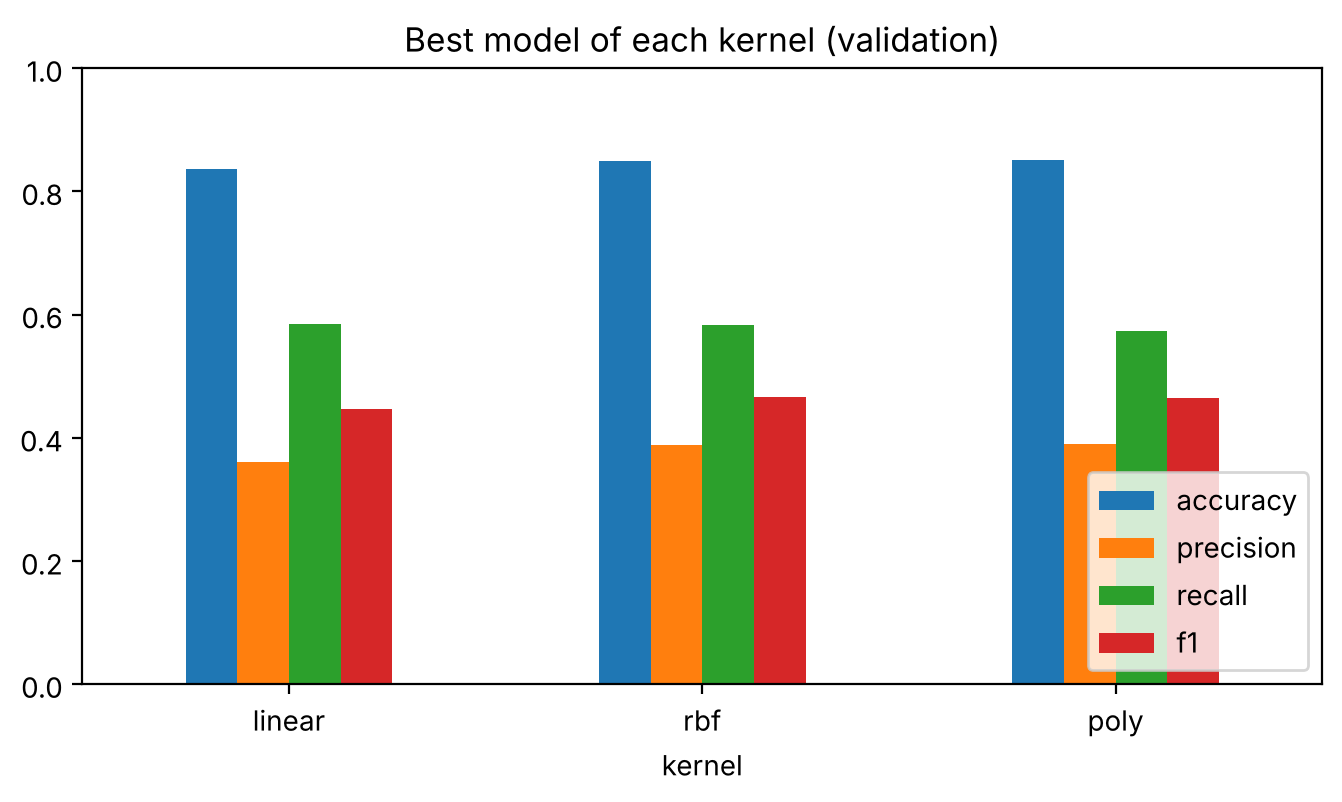

In [ ]:
best[metrics].plot(kind="bar", figsize=(8, 4), rot=0)
plt.ylim(0, 1)
plt.title("Best model of each kernel (validation)")
plt.legend(loc="lower right")
plt.show()

### 6.7 Benchmark: adding `duration` back

In [ ]:
duration_res = pd.DataFrame([evaluate(SVC(kernel="rbf", C=1, gamma="scale", class_weight="balanced"), cols),
                             evaluate(SVC(kernel="rbf", C=1, gamma="scale", class_weight="balanced"), cols + ["duration"])],
                            index=["our model (no duration)", "benchmark (with duration)"], columns=metrics)
duration_res

,accuracy,precision,recall,f1
our model (no duration),0.8496,0.3882,0.5826,0.4659
benchmark (with duration),0.8542,0.4301,0.9076,0.5837


In [ ]:
# drop duration (UCI note) and the weak features from Task 4
X_train = X_train.drop(columns=["duration"] + drop_cols)
X_test = X_test.drop(columns=["duration"] + drop_cols)
print(X_train.shape, X_test.shape)

(32940, 45) (8236, 45)


# Task 7 — Final model on Test

In [ ]:
final_model = SVC(kernel="rbf", C=1, gamma="scale", class_weight="balanced")   # best F1 in 6.6
final_model.fit(X_train, y_train)          # train on full Train
y_pred = final_model.predict(X_test)
baseline = np.zeros(len(y_test))           # always "no"

test_res = pd.DataFrame([
    [accuracy_score(y_test, baseline), 0, 0, 0],
    [accuracy_score(y_test, y_pred), precision_score(y_test, y_pred),
     recall_score(y_test, y_pred), f1_score(y_test, y_pred)]
], index=["baseline: always 'no'", "final SVM"], columns=metrics).round(4)
test_res

,accuracy,precision,recall,f1
baseline: always 'no',0.8873,0.0000,0.0000,0.0000
final SVM,0.8498,0.3962,0.6358,0.4882


In [ ]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.95      0.88      0.91      7308
           1       0.40      0.64      0.49       928

    accuracy                           0.85      8236
   macro avg       0.67      0.76      0.70      8236
weighted avg       0.89      0.85      0.86      8236



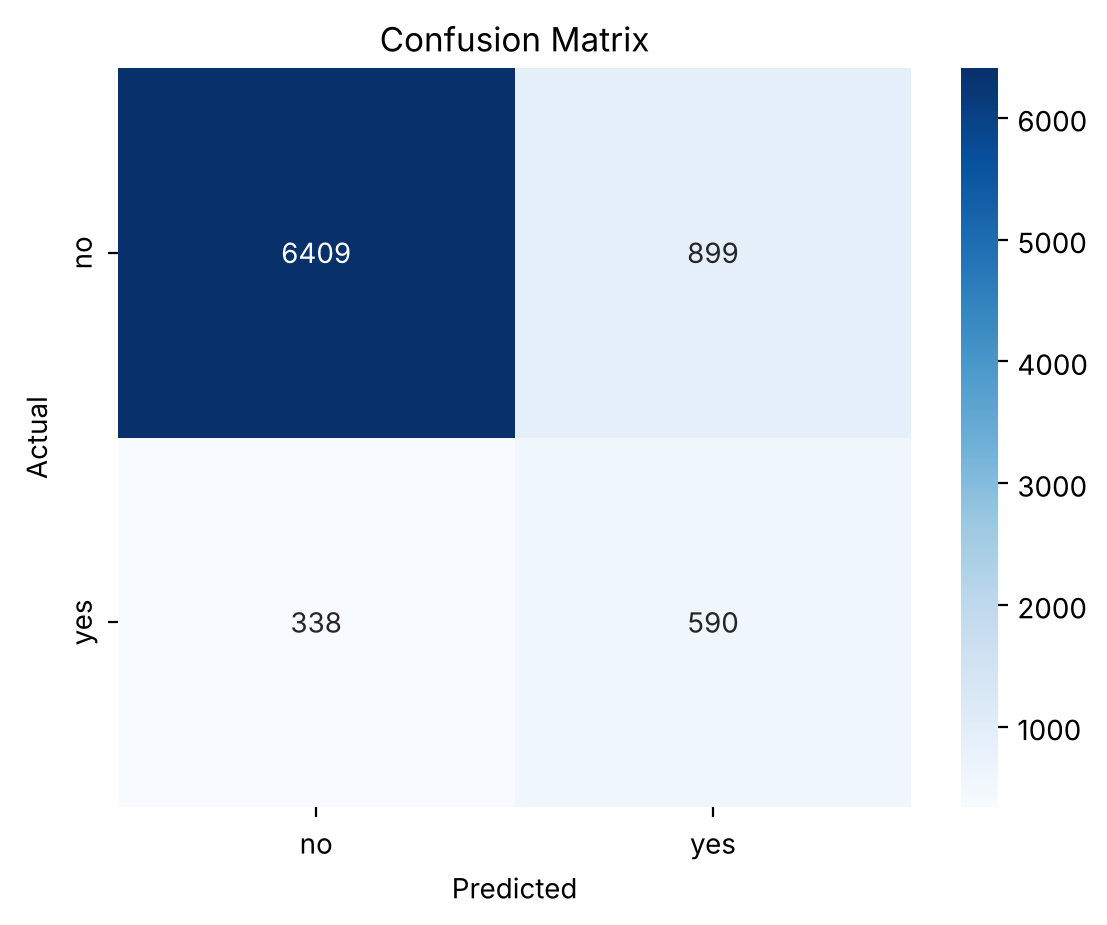

In [ ]:
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["no", "yes"], yticklabels=["no", "yes"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

In [ ]:
tn, fp, fn, tp = cm.ravel()
pd.DataFrame({"count": [tn, fp, fn, tp],
              "meaning": ["said no, model said no", "said no, model said yes (extra call)",
                          "said yes, model said no (lost client)", "said yes, model said yes"]},
             index=["TN", "FP", "FN", "TP"])

,count,meaning
TN,6409,"said no, model said no"
FP,899,"said no, model said yes (extra call)"
FN,338,"said yes, model said no (lost client)"
TP,590,"said yes, model said yes"


### Summary

In [ ]:
summary = pd.concat([
    weights_res.rename(index=lambda i: f"validation · rbf default · {i}"),
    selection_res.rename(index=lambda i: f"validation · balanced · {i} features"),
    best[metrics].rename(index=lambda k: f"validation · best {k}"),
    duration_res.rename(index=lambda i: f"validation · {i}"),
    test_res.rename(index=lambda i: f"TEST · {i}"),
])
summary

,accuracy,precision,recall,f1
validation · rbf default · no class_weight,0.8986,0.6944,0.1776,0.2829
validation · rbf default · class_weight='balanced',0.8496,0.3882,0.5826,0.4659
validation · balanced · all (55) features,0.8488,0.3871,0.5879,0.4669
validation · balanced · selected (45) features,0.8496,0.3882,0.5826,0.4659
validation · best linear,0.8368,0.3611,0.5844,0.4464
validation · best rbf,0.8496,0.3882,0.5826,0.4659
validation · best poly,0.8510,0.3901,0.5737,0.4644
validation · our model (no duration),0.8496,0.3882,0.5826,0.4659
validation · benchmark (with duration),0.8542,0.4301,0.9076,0.5837
TEST · baseline: always 'no',0.8873,0.0000,0.0000,0.0000


# Task 8 — Discussion

- The most useful attribute is euribor3m (and the other economic columns): more clients subscribe when interest rates are low.
- poutcome_success, prev_contacted and previous are useful: clients who said yes before often say yes again.
- contact (cellular) and month (mar, sep, oct, dec) are also useful.
- duration is the strongest attribute, but it is only known after the call, so it was used only as a benchmark.
- rbf and poly are slightly better than linear, so the data is not fully linear, but the difference is small.
- Removing the 10 weak features gives almost the same result with fewer features.
- Without class_weight the model finds very few yes clients (low recall).
- With class_weight="balanced" it finds many more yes clients, but with more false alarms (lower precision).
- The final model has better F1 and recall than the baseline (always no).
- The test F1 is close to the validation F1, so the model is stable.

Limitations:

1. duration can’t be used, which makes the task harder.
2. The data is imbalanced (89 / 11), so accuracy alone is not enough.
3. Precision is low, so many clients predicted as yes will say no.
4. Only one validation split was used (no cross validation).
5. Unknown values were kept as a category.
6. The data is from 2008–2010, and a random split does not test future campaigns.
7. SVM is slow on big data, so the experiments used only part of the Train data.